# Modelo 2 · Esse link é phishing?

**Desconfie · Global Solution 2026/2 · FIAP 1TDS · Artificial Intelligence & Chatbot**

Muitos golpes chegam com um link. Este modelo olha só o **formato do endereço** — tamanho, pontos,
subdomínios, HTTPS, números, palavras e domínio — e devolve a probabilidade de ser phishing. Não precisa
abrir o site, então é rápido e seguro.

| | |
|---|---|
| **Problema** | Classificação binária (phishing = 1, legítimo = 0) |
| **Dados** | `dados/urls.csv`: LegitPhish (Mendeley Data, 2025) com 101.218 URLs + 5.000 URLs brasileiras sintéticas |
| **Algoritmos comparados** | Random Forest × Regressão Logística |
| **Métrica principal** | **Recall da classe phishing**, com atenção à precisão |
| **Saída** | `modelos/url_phishing.joblib`, consumido pela API Flask |

Roteiro: dados → análise exploratória → features → preparação por domínio → treino → avaliação → exportação.

In [1]:
import sys, json, warnings
from pathlib import Path
from urllib.parse import urlparse
sys.path.append(str(Path.cwd().parent))   # features.py: o mesmo módulo que a API usa
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
from sklearn.base import clone
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve,
                             roc_auc_score, recall_score, precision_score, f1_score, accuracy_score)
from features import extrair_features, COLUNAS_URL, COLUNAS_URL_LEGITPHISH

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
AZUL, AMARELO = "#0A2540", "#FFB020"
SEMENTE = 42

## 1. Os dados

In [2]:
df = pd.read_csv("../dados/urls.csv")
print(df.shape, "| nulos:", int(df.isna().sum().sum()), "| URLs duplicadas:", df["url"].duplicated().sum())
display(df.groupby(["origem", "phishing"]).size().unstack().rename(columns={0: "legítimo", 1: "phishing"}))
df[["url", "phishing", "origem"]].head(3)

(106218, 19) | nulos: 0 | URLs duplicadas: 346


phishing,legítimo,phishing
origem,,
legitphish,37540,63678
sintetico_br,2500,2500


,url,phishing,origem
0,http://59.183.125.111:43889/i,1,legitphish
1,http://194.120.230.54/hiddenbin/boatnet.arm,1,legitphish
2,https://www.stemsaflowershop.com,0,legitphish


## 2. Análise exploratória

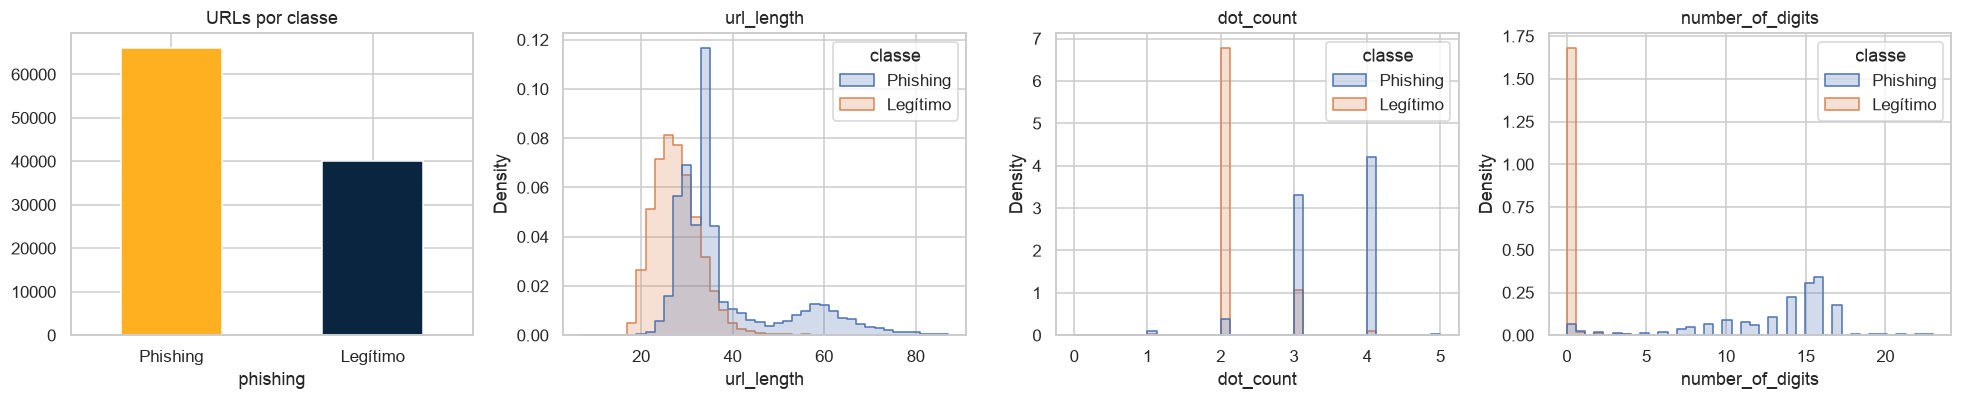

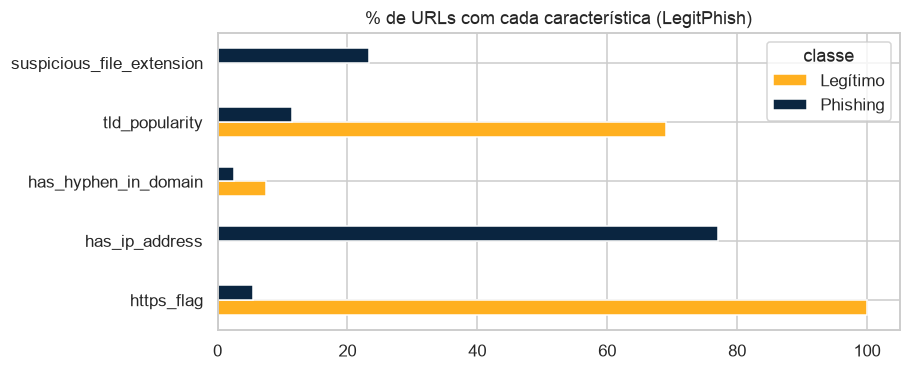

classe,Legítimo,Phishing
https_flag,100.0,5.5
has_ip_address,0.0,77.1
has_hyphen_in_domain,7.4,2.5
tld_popularity,69.1,11.5
suspicious_file_extension,0.0,23.3


In [3]:
lp = df[df["origem"] == "legitphish"].assign(classe=lambda d: d["phishing"].map({0: "Legítimo", 1: "Phishing"}))

fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
df["phishing"].map({0: "Legítimo", 1: "Phishing"}).value_counts().plot.bar(ax=ax[0], color=[AMARELO, AZUL], rot=0)
ax[0].set_title("URLs por classe")
for a, c in zip(ax[1:], ["url_length", "dot_count", "number_of_digits"]):
    sns.histplot(data=lp[lp[c] <= lp[c].quantile(0.99)], x=c, hue="classe", bins=40,
                 element="step", stat="density", common_norm=False, ax=a)
    a.set_title(c)
plt.tight_layout(); plt.show()

binarias = ["https_flag", "has_ip_address", "has_hyphen_in_domain", "tld_popularity", "suspicious_file_extension"]
tab = (lp.groupby("classe")[binarias].mean().T * 100).round(1)
tab.plot.barh(figsize=(8, 3.5), color=[AMARELO, AZUL])
plt.title("% de URLs com cada característica (LegitPhish)"); plt.show()
tab

**O que vemos, e um problema importante:**

- As classes estão em ~62% phishing / 38% legítimo. Desbalanceado, mas não muito; usamos
  `class_weight="balanced"` mesmo assim.
- No LegitPhish, **100% dos links legítimos usam HTTPS** contra ~5% dos de phishing, e **77% dos links de
  phishing usam um IP** no lugar do domínio.
- Um modelo treinado só com isso aprende um atalho: "tem HTTPS e não tem IP → legítimo". Na vida real o golpe
  brasileiro típico **tem HTTPS e domínio próprio**: `https://itau-seguranca-app.xyz/login`. Testamos:
  treinado só no LegitPhish, o modelo dava **14%** de chance de phishing para esse link.

**O que fizemos:**

1. Acrescentamos **5.000 URLs brasileiras sintéticas** (`origem = sintetico_br`): 2.500 de domínios oficiais
   (bancos, gov.br, Correios, lojas) e 2.500 no padrão dos golpes (`marca-palavra.xyz`, marca no subdomínio,
   HTTPS na maioria).
2. Criamos **2 features novas** em `features.py`: `suspicious_word_count` (login, segurança, atualiza,
   desbloqueio, pix…) e `suspicious_tld` (.xyz, .top, .online…).

## 3. As features, recalculadas pelo código da API

A API recebe **só o link** e precisa produzir as mesmas colunas. Então recalculamos tudo com
`features.extrair_features(url)` — a **mesma função** da API — e conferimos contra as colunas originais do
LegitPhish antes de treinar.

In [4]:
feat = pd.DataFrame([extrair_features(u) for u in df["url"]], index=df.index)
X_all, y_all = feat[COLUNAS_URL], df["phishing"]

m = df["origem"] == "legitphish"
concordancia = pd.Series({c: np.isclose(df.loc[m, c], feat.loc[m, c], atol=0.01).mean()
                          for c in COLUNAS_URL_LEGITPHISH}, name="% igual ao original") * 100
display(concordancia.round(1).to_frame())

def dominio_registrado(url):
    # itau.com.br, gov.br, google.com: o "dono" do endereco, sem subdominios
    partes = (urlparse(url if "://" in url else "http://" + url).hostname or "").split(".")
    if len(partes) >= 3 and partes[-2] in {"com", "gov", "org", "net", "edu", "co", "ac"}:
        return ".".join(partes[-3:])
    return ".".join(partes[-2:])

df["dominio"] = df["url"].map(dominio_registrado)
(X_all.assign(classe=y_all.map({0: "Legítimo", 1: "Phishing"}), origem=df["origem"])
      .groupby(["origem", "classe"])[["https_flag", "has_ip_address", "suspicious_tld", "suspicious_word_count"]]
      .mean().round(2))

,% igual ao original
url_length,100.0
has_ip_address,100.0
dot_count,100.0
https_flag,100.0
url_entropy,100.0
token_count,99.1
subdomain_count,98.7
query_param_count,100.0
tld_length,98.7
path_length,98.7


https_flag  has_ip_address  suspicious_tld  \
origem       classe                                                 
legitphish   Legítimo        1.00            0.00            0.01   
             Phishing        0.06            0.77            0.02   
sintetico_br Legítimo        0.72            0.00            0.00   
             Phishing        0.70            0.00            0.77   

                       suspicious_word_count  
origem       classe                           
legitphish   Legítimo                   0.00  
             Phishing                   0.02  
sintetico_br Legítimo                   0.40  
             Phishing                   1.33

**O que vemos:** as 16 colunas do LegitPhish batem em 98–100% das linhas — as diferenças vêm de URLs sem
`http://` no começo, que tratamos de forma mais robusta. Daqui em diante o treino usa **as nossas 18 features**.

E, nas URLs brasileiras, legítimas e golpes **usam HTTPS na mesma proporção**: o modelo é obrigado a olhar
outras coisas (palavras suspeitas, TLD, hífen) para separar. Era esse o objetivo de acrescentá-las.

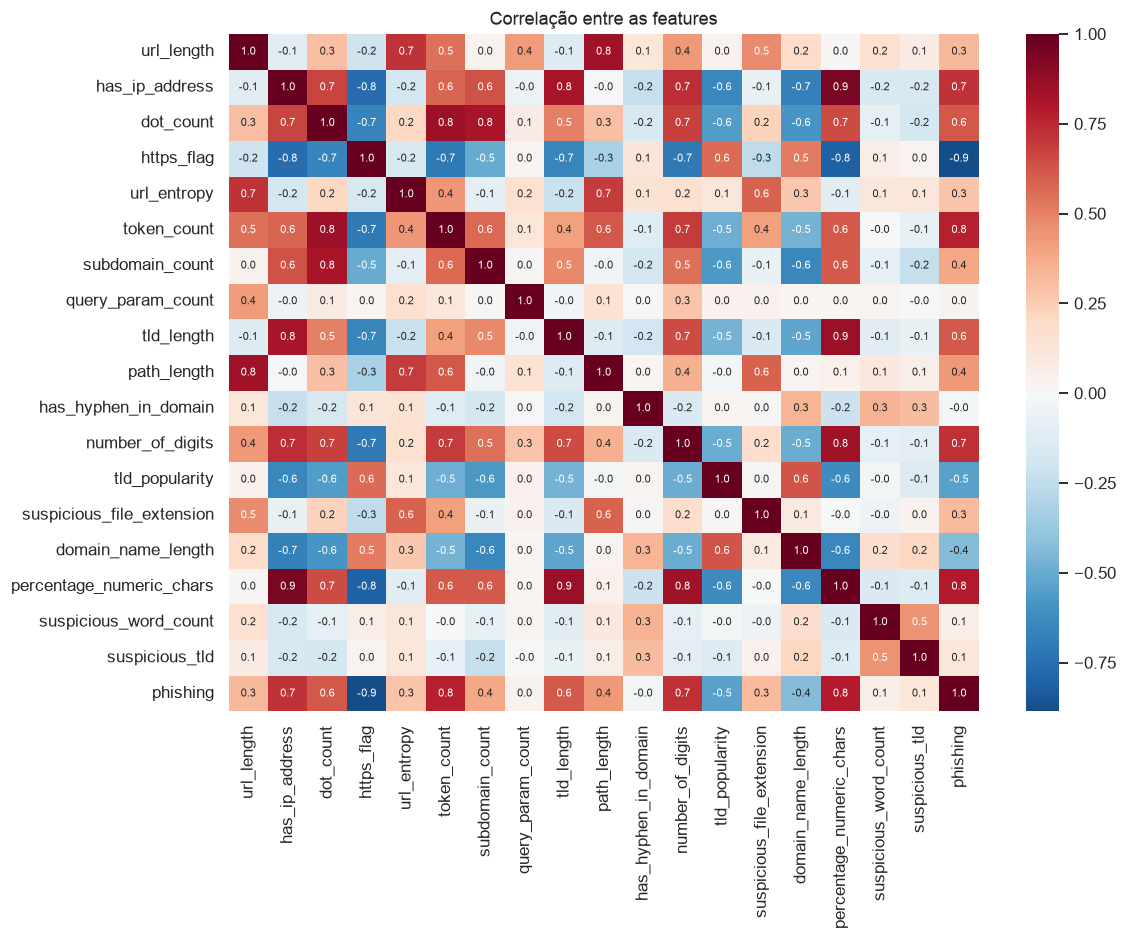

Domínios distintos: 60416

Domínios que mais repetem:
dominio                   phishing
cumpar-auto-orice-tip.ro  1           965
healthnlife.pk            1           924
powerforxes.shop          1           770
uniformeslaamistad.com    1           768
mugutu.com                1           766
veritas.org.ng            1           718
esalesin.com              1           692
johnmccrea.com            1           689


In [5]:
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(X_all.assign(phishing=y_all).corr(), cmap="RdBu_r", center=0, annot=True, fmt=".1f",
            annot_kws={"size": 7}, ax=ax)
ax.set_title("Correlação entre as features"); plt.show()

print("Domínios distintos:", df["dominio"].nunique())
print("\nDomínios que mais repetem:")
print(df.groupby(["dominio", "phishing"]).size().sort_values(ascending=False).head(8).to_string())

**O que vemos:** `url_length`, `number_of_digits` e `percentage_numeric_chars` andam juntas. Para a Random
Forest isso não atrapalha; para a Regressão Logística, padronizamos as escalas com `StandardScaler`.

E alguns domínios de phishing aparecem **centenas de vezes**. Numa separação aleatória o mesmo domínio cairia
no treino e no teste, o modelo "decoraria" o domínio e a métrica ficaria inflada.

**Decisão:** separar treino e teste **por domínio** (`GroupShuffleSplit`). Um domínio inteiro fica só no
treino ou só no teste — como aconteceria com links novos de verdade.

## 4. Preparação: separação por domínio

In [6]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEMENTE)
i_tr, i_te = next(gss.split(X_all, y_all, groups=df["dominio"]))
X_treino, X_teste = X_all.iloc[i_tr], X_all.iloc[i_te]
y_treino, y_teste = y_all.iloc[i_tr], y_all.iloc[i_te]
origem_teste = df["origem"].iloc[i_te].values

print("Domínios em comum entre treino e teste:",
      len(set(df["dominio"].iloc[i_tr]) & set(df["dominio"].iloc[i_te])))
pd.DataFrame({"linhas": [len(X_treino), len(X_teste)], "% phishing": [y_treino.mean(), y_teste.mean()]},
             index=["treino", "teste"]).round(3)

Domínios em comum entre treino e teste: 0


,linhas,% phishing
treino,82693,0.615
teste,23525,0.651


## 5. Treinamento

- **Random Forest:** muitas árvores votando. Lida bem com escalas diferentes e com combinações do tipo
  "HTTPS **mas** TLD suspeito **e** palavra de segurança".
- **Regressão Logística:** linear, simples e rápida, como base de comparação. Precisa das features
  padronizadas.

Validação cruzada com `GroupKFold` (5 partes, também separando por domínio).

In [7]:
modelos = {
    "Random Forest": RandomForestClassifier(n_estimators=150, max_depth=22, min_samples_leaf=2,
                                            class_weight="balanced", n_jobs=-1, random_state=SEMENTE),
    "Regressão Logística": Pipeline([("esc", StandardScaler()),
                                     ("clf", LogisticRegression(class_weight="balanced", max_iter=2000))]),
}

grupos_treino = df["dominio"].iloc[i_tr]
pd.DataFrame([
    {"modelo": nome, **{k.replace("test_", ""): f"{v.mean():.3f} ± {v.std():.3f}"
                        for k, v in cross_validate(m, X_treino, y_treino, groups=grupos_treino,
                                                   cv=GroupKFold(n_splits=5), n_jobs=1,
                                                   scoring=["recall", "precision", "f1", "roc_auc"]).items()
                        if k.startswith("test_")}}
    for nome, m in modelos.items()]).set_index("modelo")

,recall,precision,f1,roc_auc
modelo,,,,
Random Forest,0.998 ± 0.001,0.993 ± 0.008,0.995 ± 0.004,1.000 ± 0.000
Regressão Logística,0.989 ± 0.004,0.996 ± 0.002,0.992 ± 0.002,0.999 ± 0.000


## 6. Avaliação no teste

Olhamos o teste em três cortes: tudo junto, só LegitPhish e só as URLs brasileiras. O terceiro é o que mais
interessa ao Desconfie, e é também o mais difícil.

In [8]:
def metricas(y, p, lim=0.5):
    pred = (p >= lim).astype(int)
    return {"recall (phishing)": recall_score(y, pred), "precisão (phishing)": precision_score(y, pred),
            "F1": f1_score(y, pred), "acurácia": accuracy_score(y, pred), "ROC AUC": roc_auc_score(y, p)}

cortes = [("todo o teste", np.ones(len(y_teste), bool)),
          ("só LegitPhish", origem_teste == "legitphish"),
          ("só sintéticas BR", origem_teste == "sintetico_br")]

probs, linhas = {}, []
for nome, m in modelos.items():
    m.fit(X_treino, y_treino)
    probs[nome] = m.predict_proba(X_teste)[:, 1]
    linhas += [{"modelo": nome, "parte": parte, **metricas(y_teste[f], probs[nome][f])} for parte, f in cortes]

tabela = pd.DataFrame(linhas).set_index(["modelo", "parte"]).round(3)
escolhido = tabela.xs("todo o teste", level="parte")["F1"].idxmax()
modelo = modelos[escolhido]
print("Modelo escolhido (maior F1 no teste):", escolhido, "\n")
print(classification_report(y_teste, (probs[escolhido] >= 0.5).astype(int),
                            target_names=["Legítimo", "Phishing"], digits=3))
tabela

Modelo escolhido (maior F1 no teste): Random Forest 

              precision    recall  f1-score   support

    Legítimo      0.997     0.981     0.989      8213
    Phishing      0.990     0.998     0.994     15312

    accuracy                          0.992     23525
   macro avg      0.993     0.990     0.992     23525
weighted avg      0.992     0.992     0.992     23525



recall (phishing)  precisão (phishing)  \
modelo              parte                                                      
Random Forest       todo o teste                  0.998                0.990   
                    só LegitPhish                 0.999                0.994   
                    só sintéticas BR              0.984                0.870   
Regressão Logística todo o teste                  0.988                0.995   
                    só LegitPhish                 0.990                0.999   
                    só sintéticas BR              0.922                0.889   

                                         F1  acurácia  ROC AUC  
modelo              parte                                       
Random Forest       todo o teste      0.994     0.992    1.000  
                    só LegitPhish     0.997     0.996    1.000  
                    só sintéticas BR  0.923     0.913    0.990  
Regressão Logística todo o teste      0.992     0.989    0.999  
                    só LegitPhish     0.995     0.993    0.999  
                    só sintéticas BR  0.905     0.897    0.967

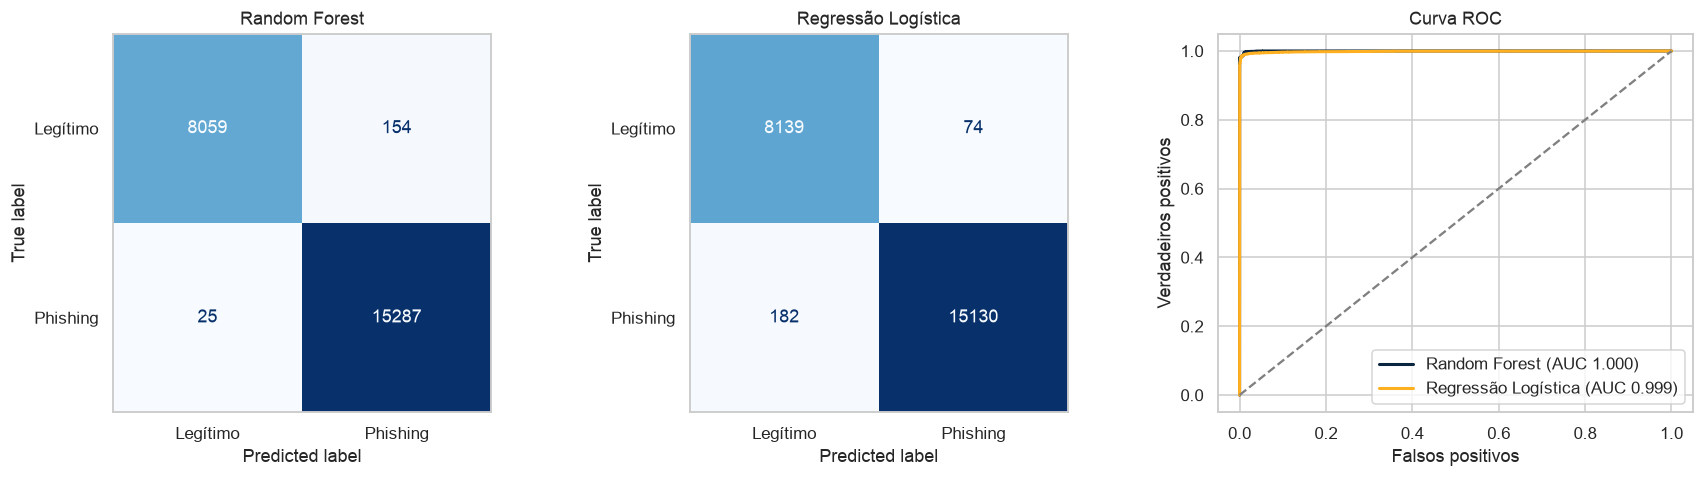

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, (nome, p) in zip(ax, probs.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_teste, (p >= 0.5).astype(int)),
                           display_labels=["Legítimo", "Phishing"]).plot(ax=a, cmap="Blues",
                                                                          colorbar=False, values_format="d")
    a.set_title(nome); a.grid(False)
for (nome, p), cor in zip(probs.items(), [AZUL, AMARELO]):
    fpr, tpr, _ = roc_curve(y_teste, p)
    ax[2].plot(fpr, tpr, color=cor, lw=2, label=f"{nome} (AUC {roc_auc_score(y_teste, p):.3f})")
ax[2].plot([0, 1], [0, 1], "--", color="grey")
ax[2].set(title="Curva ROC", xlabel="Falsos positivos", ylabel="Verdadeiros positivos"); ax[2].legend(loc="lower right")
plt.tight_layout(); plt.show()

## 7. Quais características mais pesam

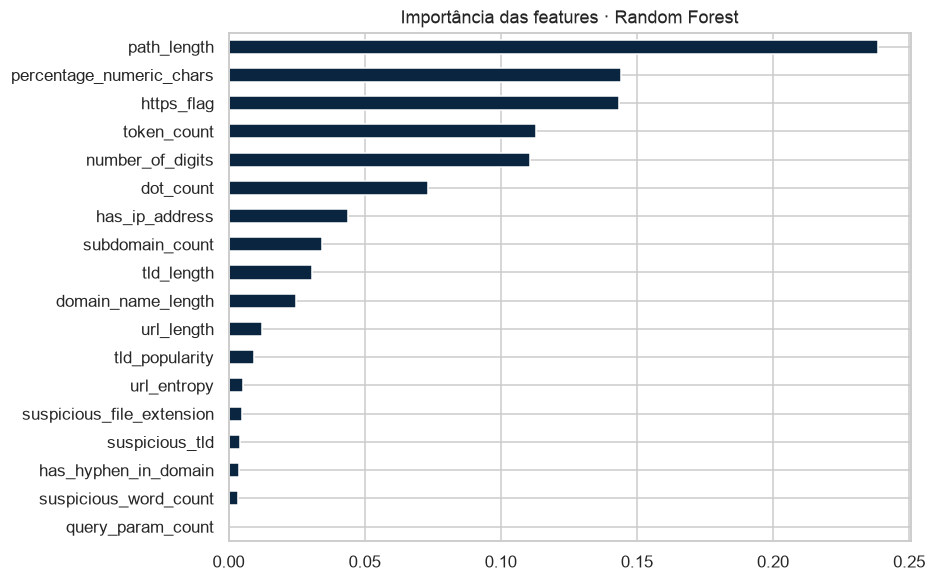

,importância
path_length,0.239
percentage_numeric_chars,0.144
https_flag,0.144
token_count,0.113
number_of_digits,0.111
dot_count,0.073
has_ip_address,0.044
subdomain_count,0.034
tld_length,0.031
domain_name_length,0.025


In [10]:
if hasattr(modelo, "feature_importances_"):
    imp = pd.Series(modelo.feature_importances_, index=COLUNAS_URL).sort_values()
    imp.plot.barh(figsize=(8, 6), color=AZUL)
    plt.title(f"Importância das features · {escolhido}"); plt.show()
    display(imp.sort_values(ascending=False).round(3).to_frame("importância"))

## 8. Testando com links que o cidadão recebe (escritos à mão, fora do conjunto de dados)

In [11]:
links = [
    "https://itau-seguranca-app.xyz/login",
    "http://correios-taxa.top/pagar?id=88123",
    "https://nubank-desbloqueio.online/acesso",
    "https://caixa.com.br.regulariza-pix.site",
    "http://192.168.10.5/bb/atualizar.php",
    "https://meu-premio-shopee.store/resgatar",
    "https://www.itau.com.br",
    "https://www.gov.br/receitafederal/pt-br",
    "https://rastreamento.correios.com.br/app/index.php",
    "https://www.mercadolivre.com.br/ofertas",
    "https://github.com/fiap",
]
Xl = pd.DataFrame([extrair_features(u) for u in links])[COLUNAS_URL]
pd.DataFrame({"link": links, **{n: m.predict_proba(Xl)[:, 1].round(3) for n, m in modelos.items()}})

,link,Random Forest,Regressão Logística
0,https://itau-seguranca-app.xyz/login,1.000,0.999
1,http://correios-taxa.top/pagar?id=88123,1.000,1.000
2,https://nubank-desbloqueio.online/acesso,1.000,1.000
3,https://caixa.com.br.regulariza-pix.site,0.990,0.934
4,http://192.168.10.5/bb/atualizar.php,0.970,1.000
5,https://meu-premio-shopee.store/resgatar,1.000,0.999
6,https://www.itau.com.br,0.000,0.000
7,https://www.gov.br/receitafederal/pt-br,0.078,0.002
8,https://rastreamento.correios.com.br/app/index...,0.413,0.774
9,https://www.mercadolivre.com.br/ofertas,0.009,0.001


**O que vemos:** com as URLs brasileiras e as duas features novas, os golpes no formato `marca-palavra.xyz`
passam a ser reconhecidos **mesmo com HTTPS**. O modelo continua olhando só o formato — um site falso com
endereço curto e limpo pode passar. Por isso, no Desconfie, ele é um sinal entre vários, e a regra
`DOMINIO_IMITA_MARCA` (nome de banco num domínio que não é o oficial) é verificada à parte pela API Java.

## 9. Exportação

O modelo escolhido é retreinado com **todos os dados** e salvo em `.joblib`; o limiar, a lista ordenada das
18 features e as métricas vão num `.json` ao lado. A ordem das colunas importa: a API monta o `DataFrame`
seguindo exatamente essa lista.

In [12]:
final = clone(modelo).fit(X_all, y_all)

Path("../modelos").mkdir(exist_ok=True)
joblib.dump(final, "../modelos/url_phishing.joblib", compress=3)
meta = {"modelo": escolhido, "limiar": 0.5, "features": COLUNAS_URL,
        "metricas_teste_por_dominio": tabela.loc[escolhido].to_dict(orient="index"),
        "linhas_treino_final": int(len(X_all))}
Path("../modelos/url_phishing.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2))
print(json.dumps(meta["metricas_teste_por_dominio"], ensure_ascii=False, indent=2))
print("Tamanho do .joblib: %.1f MB" % (Path("../modelos/url_phishing.joblib").stat().st_size / 1e6))

# confere que o arquivo salvo carrega e responde
carregado = joblib.load("../modelos/url_phishing.joblib")
print("teste de carga:",
      carregado.predict_proba(pd.DataFrame([extrair_features("https://caixa-regulariza.xyz/pix")])[COLUNAS_URL])[0, 1].round(3))

{
  "todo o teste": {
    "recall (phishing)": 0.998,
    "precisão (phishing)": 0.99,
    "F1": 0.994,
    "acurácia": 0.992,
    "ROC AUC": 1.0
  },
  "só LegitPhish": {
    "recall (phishing)": 0.999,
    "precisão (phishing)": 0.994,
    "F1": 0.997,
    "acurácia": 0.996,
    "ROC AUC": 1.0
  },
  "só sintéticas BR": {
    "recall (phishing)": 0.984,
    "precisão (phishing)": 0.87,
    "F1": 0.923,
    "acurácia": 0.913,
    "ROC AUC": 0.99
  }
}
Tamanho do .joblib: 2.1 MB
teste de carga: 1.0


## 10. Conclusões

Teste separado por domínio — nenhum domínio do teste apareceu no treino. Os números exatos estão na tabela da
seção 6 e em `modelos/url_phishing.json`.

- **Escolhemos a Random Forest.** Maior recall e maior F1, e a diferença aparece onde mais importa: nas URLs
  brasileiras ela deixa passar ~1,6% dos golpes, contra ~7,8% da Regressão Logística.
- **As métricas no LegitPhish (~0,99) são altas demais para confiar só nelas.** A base tem atalhos: todo link
  legítimo usa HTTPS e a maioria dos de phishing usa IP. Treinado só nela, o modelo dava 14% de chance de
  phishing para `https://itau-seguranca-app.xyz/login`; com as URLs brasileiras e as features novas, esse
  link passa a receber ~100%.
- **O número realista é o das URLs brasileiras:** recall alto com precisão em torno de 0,87 — quase nenhum
  golpe passa, mas cerca de 1 em cada 8 alertas é um link legítimo. Exemplo:
  `rastreamento.correios.com.br/app/index.php` recebe ~41%, por ter caminho longo terminando em `.php`.
- **O que mais pesa:** tamanho do caminho, HTTPS, quantidade de números e de pontos. HTTPS ainda pesa muito
  por causa do viés do LegitPhish — vale dizer isso na apresentação.
- **O modelo é um sinal, não o juiz:** a probabilidade entra no cálculo da API Java junto com as regras.
- **Próximo passo:** coletar links reais de golpes brasileiros (denúncias, prints de SMS) para substituir as
  URLs sintéticas.